# Heart Disease Prediction System

**Student Name:** LEENA QAISAR

**Registration Number:** FA24-BSE-058 

**Assignment:** Machine Learning Assignment 02

## Introduction

This project predicts whether heart disease is present or absent using
the processed Cleveland dataset from the UCI Machine Learning Repository.

The project follows the workflow of the provided Titanic prediction
notebook: importing libraries, loading data, preprocessing, feature
selection, encoding, training, testing, prediction and feedback.

A Support Vector Classifier (SVC) is used for classification.

This is an educational project. Its predictions are not medical diagnoses.

## Dataset Source

Janosi, A., Steinbrunn, W., Pfisterer, M., & Detrano, R. (1989).
Heart Disease. UCI Machine Learning Repository.

- Dataset: https://archive.ics.uci.edu/dataset/45/heart+disease
- DOI: https://doi.org/10.24432/C52P4X
- Reference notebook: https://github.com/haqnawaz99/ml-teaching-notebooks

## Step 1: Install and Import Libraries

The following libraries are used:

| Library | Purpose |
|---|---|
| pandas | Load and manage data |
| numpy | Perform numerical operations |
| matplotlib and seaborn | Visualize data and results |
| scikit-learn | Preprocess, train and evaluate the model |
| pickle | Save and load the trained model |

Run the installation cell once. If prompted, restart the kernel and
continue with the import cell.

In [278]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [279]:
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile
from io import BytesIO
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score
)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix,
    RocCurveDisplay
)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")
print("Working folder:", Path.cwd())

Libraries imported successfully.
Working folder: c:\Users\User\Desktop\Heart_Disease_Prediction


## Step 2: Load the Dataset

The original processed Cleveland dataset contains 303 observations,
13 input features and one diagnosis column called `num`.

The code downloads the dataset directly from UCI and creates
`processed_cleveland.csv` in the working folder.

Missing values, originally represented by `?`, are read as NaN.
If the CSV already exists, it is loaded without downloading again.

Source: https://archive.ics.uci.edu/dataset/45/heart+disease

In [280]:
columns = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num"
]

csv_path = Path("processed_cleveland.csv")

if csv_path.exists():
    data = pd.read_csv(csv_path)
    print("Loaded the local CSV.")
else:
    url = "https://archive.ics.uci.edu/static/public/45/heart+disease.zip"

    with urlopen(url, timeout=60) as response:
        downloaded_data = response.read()

    with ZipFile(BytesIO(downloaded_data)) as archive:
        with archive.open("processed.cleveland.data") as file:
            data = pd.read_csv(
                file,
                header=None,
                names=columns,
                na_values="?"
            )

    data.to_csv(csv_path, index=False)
    print("Downloaded the dataset and saved the CSV.")

print("Dataset shape:", data.shape)
data.head()

Loaded the local CSV.
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


## Step 3: Understand and Preprocess the Data

### Step 3.1: Understand the Features

The dataset uses the following original UCI codes:

| Feature | Description |
|---|---|
| age | Age in years |
| sex | 0 = female; 1 = male |
| cp | Chest pain: 1 = typical angina; 2 = atypical angina; 3 = non-anginal pain; 4 = asymptomatic |
| trestbps | Resting blood pressure in mm Hg |
| chol | Serum cholesterol in mg/dL |
| fbs | Fasting blood sugar >120 mg/dL: 0 = false; 1 = true |
| restecg | Resting ECG: 0 = normal; 1 = ST-T abnormality; 2 = probable/definite left ventricular hypertrophy |
| thalach | Maximum heart rate achieved |
| exang | Exercise-induced angina: 0 = no; 1 = yes |
| oldpeak | ST depression induced by exercise relative to rest |
| slope | Peak exercise ST slope: 1 = upsloping; 2 = flat; 3 = downsloping |
| ca | Number of major vessels coloured by fluoroscopy, from 0 to 3 |
| thal | 3 = normal; 6 = fixed defect; 7 = reversible defect |
| num | Original diagnosis label, from 0 to 4 |

Source: https://archive.ics.uci.edu/dataset/45/heart+disease

In [281]:
print("Dataset information:")
data.info()

print("\nMissing values:")
print(data.isna().sum())

print("\nDuplicate rows:", data.duplicated().sum())

print("\nOriginal diagnosis counts:")
print(data["num"].value_counts().sort_index())

print("\nStatistical summary:")
data.describe().round(2)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    float64
 1   sex       303 non-null    float64
 2   cp        303 non-null    float64
 3   trestbps  303 non-null    float64
 4   chol      303 non-null    float64
 5   fbs       303 non-null    float64
 6   restecg   303 non-null    float64
 7   thalach   303 non-null    float64
 8   exang     303 non-null    float64
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    float64
 11  ca        299 non-null    float64
 12  thal      301 non-null    float64
 13  num       303 non-null    int64  
dtypes: float64(13), int64(1)
memory usage: 33.3 KB

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
num       

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
count,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,303.00,299.00,301.00,303.00
mean,54.44,0.68,3.16,131.69,246.69,0.15,0.99,149.61,0.33,1.04,1.60,0.67,4.73,0.94
std,9.04,0.47,0.96,17.60,51.78,0.36,0.99,22.88,0.47,1.16,0.62,0.94,1.94,1.23
min,29.00,0.00,1.00,94.00,126.00,0.00,0.00,71.00,0.00,0.00,1.00,0.00,3.00,0.00
25%,48.00,0.00,3.00,120.00,211.00,0.00,0.00,133.50,0.00,0.00,1.00,0.00,3.00,0.00
50%,56.00,1.00,3.00,130.00,241.00,0.00,1.00,153.00,0.00,0.80,2.00,0.00,3.00,0.00
75%,61.00,1.00,4.00,140.00,275.00,0.00,2.00,166.00,1.00,1.60,2.00,1.00,7.00,2.00
max,77.00,1.00,4.00,200.00,564.00,1.00,2.00,202.00,1.00,6.20,3.00,3.00,7.00,4.00


### Step 3.2: Preprocessing Plan

All observations are retained.

Missing feature values will be filled using the most frequent value
from the training data. This keeps imputed categorical values within
the original UCI codes.

Features will then be standardized before training the SVC model.

Imputation and scaling are performed inside a pipeline after splitting
the dataset. They learn only from training data, preventing test-data
leakage.

Source: https://scikit-learn.org/stable/common_pitfalls.html

## Exploratory Data Analysis

The following graphs describe:

1. The number of observations with and without heart disease.
2. The age distribution for each class.
3. Correlations between numerical feature codes and the binary target.

These plots are descriptive. Correlation does not establish causation,
and category-code correlations should be interpreted cautiously.

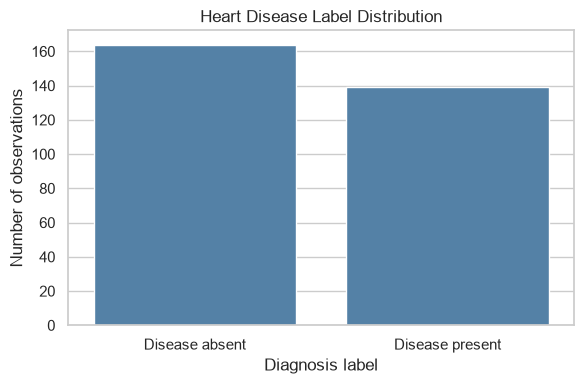

In [282]:
# Temporary labels for descriptive plots
eda_target = (data["num"] > 0).astype(int)

eda_data = data.drop(columns="num").copy()
eda_data["target"] = eda_target

plt.figure(figsize=(6, 4))

sns.countplot(
    data=eda_data,
    x="target",
    color="steelblue"
)

plt.xticks([0, 1], ["Disease absent", "Disease present"])
plt.title("Heart Disease Label Distribution")
plt.xlabel("Diagnosis label")
plt.ylabel("Number of observations")

plt.tight_layout()
plt.show()

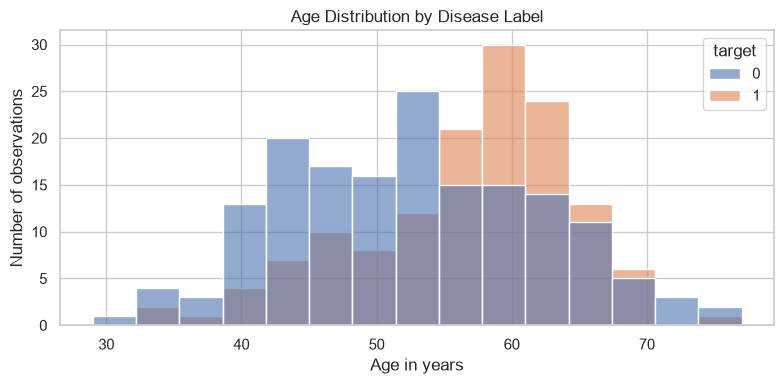

In [283]:
plt.figure(figsize=(8, 4))

sns.histplot(
    data=eda_data,
    x="age",
    hue="target",
    bins=15,
    multiple="layer",
    alpha=0.6
)

plt.title("Age Distribution by Disease Label")
plt.xlabel("Age in years")
plt.ylabel("Number of observations")

plt.tight_layout()
plt.show()

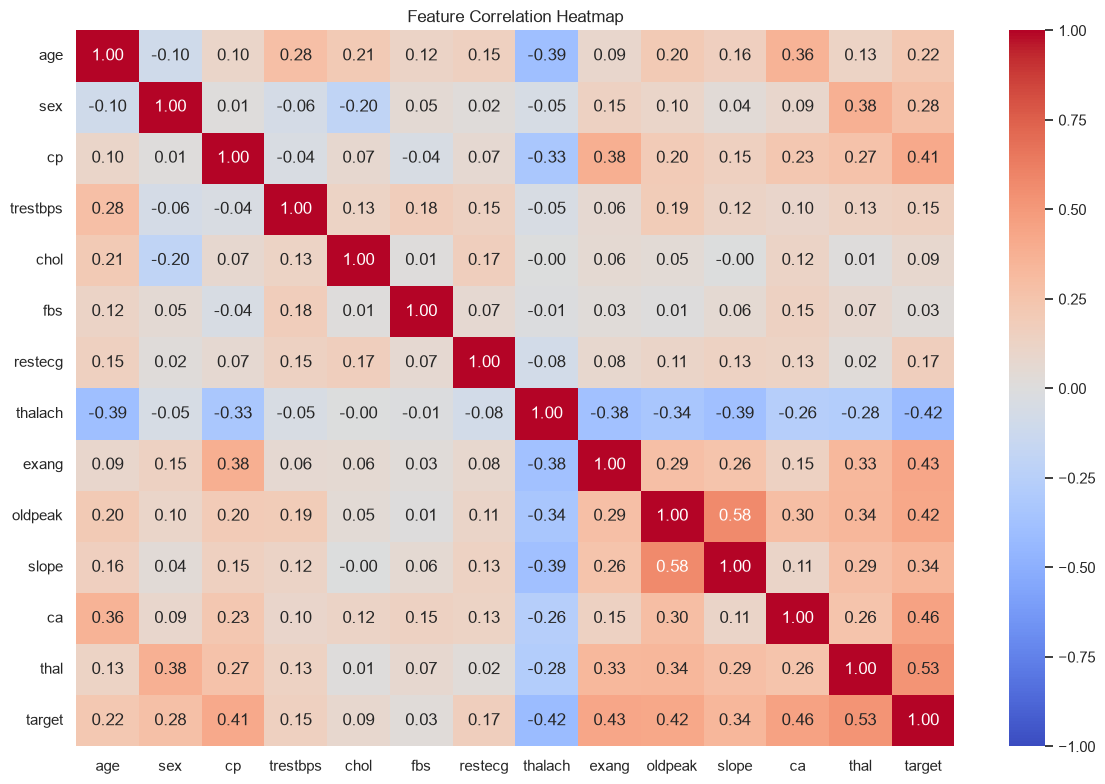

In [284]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    eda_data.corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1
)

plt.title("Feature Correlation Heatmap")

plt.tight_layout()
plt.show()

## Step 4: Feature Extraction

All 13 standard clinical input features are selected.

The original diagnosis column `num` is excluded from the inputs because
it contains the answer we want to predict.

In [285]:
features = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal"
]

X = data[features].copy()

print("Selected features:", features)
print("Input shape:", X.shape)

X.head()

Selected features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']
Input shape: (303, 13)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0


## Step 5: Encode the Inputs and Output

### Input Encoding

The input categories are already represented by numerical UCI codes,
so an additional LabelEncoder is unnecessary.

These codes are retained to follow the reference notebook's simple
SVC approach. However, numeric category codes imply distances between
categories; one-hot encoding is a possible future improvement.

### Output Encoding

The original diagnosis is converted into a binary target:

- `num = 0` → target 0: disease absent.
- `num = 1, 2, 3 or 4` → target 1: disease present.

Source: https://archive.ics.uci.edu/dataset/45/heart+disease

In [286]:
y = (data["num"] > 0).astype(int)
y.name = "target"

print("Binary target counts:")
print(y.value_counts().sort_index())

label_comparison = pd.DataFrame({
    "original_num": data["num"],
    "binary_target": y
})

label_comparison.head(10)

Binary target counts:
target
0    164
1    139
Name: count, dtype: int64


,original_num,binary_target
0,0,0
1,2,1
2,1,1
3,0,0
4,0,0
5,0,0
6,3,1
7,0,0
8,2,1
9,1,1


## Step 6: Execute the Training Phase

### Step 6.1: Split the Dataset

The dataset is divided into:

- 80% training data.
- 20% testing data.

Stratification maintains similar class proportions in both subsets.
A fixed random state makes the split reproducible.

The test set is held aside during preprocessing and training.

In [287]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))

print("\nTraining label counts:")
print(y_train.value_counts().sort_index())

print("\nTesting label counts:")
print(y_test.value_counts().sort_index())

Training observations: 242
Testing observations: 61

Training label counts:
target
0    131
1    111
Name: count, dtype: int64

Testing label counts:
target
0    33
1    28
Name: count, dtype: int64


### Step 6.2: Build the Preprocessing and Training Pipeline

The pipeline contains:

1. SimpleImputer: fills missing inputs using the most frequent training value.
2. StandardScaler: standardizes feature values.
3. SVC: trains a Support Vector Classifier with an RBF kernel.

The model uses fixed settings: C = 1 and gamma = "scale".
The test set is not used to select these settings.

Sources:
- https://scikit-learn.org/stable/common_pitfalls.html
- https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

In [288]:
model = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale"
    ))
])

model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


### Step 6.3: Training-Only Cross-Validation

Five-fold stratified cross-validation is performed using only the
training subset.

For each fold, the complete pipeline is fitted on that fold's training
portion and evaluated on its validation portion.

The mean accuracy summarizes performance across folds. The standard
deviation describes variation between fold scores.

Source: https://scikit-learn.org/stable/modules/cross_validation.html

In [289]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = cross_val_score(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy"
)

print("Fold accuracies:", np.round(cv_scores, 4))
print(f"Mean CV accuracy: {cv_scores.mean():.2%}")
print(f"CV standard deviation: {cv_scores.std():.4f}")

Fold accuracies: [0.8571 0.7959 0.7917 0.8333 0.8333]
Mean CV accuracy: 82.23%
CV standard deviation: 0.0249


### Step 6.4: Save the Trained Model

The entire fitted pipeline is saved, including imputation, scaling
and the SVC classifier.

This allows predictions without retraining and ensures that new inputs
receive the same preprocessing.

Only load pickle files from trusted sources.

Source: https://scikit-learn.org/stable/model_persistence.html

In [290]:
with open("heart_disease_model.pkl", "wb") as file:
    pickle.dump(model, file)

print("Saved heart_disease_model.pkl")

Saved heart_disease_model.pkl


## Step 7: Execute the Testing Phase

### Step 7.1–7.3: Load the Saved Model and Make Predictions

The saved pipeline is loaded and applied to the held-out test set.

SVC decision scores are also calculated for ROC-AUC evaluation.
These scores are not disease probabilities.

In [291]:
with open("heart_disease_model.pkl", "rb") as file:
    loaded_model = pickle.load(file)

y_pred = loaded_model.predict(X_test)
decision_scores = loaded_model.decision_function(X_test)

prediction_results = X_test.copy()
prediction_results["actual"] = y_test
prediction_results["predicted"] = y_pred

# Confirm that saving and loading preserved the predictions
assert np.array_equal(
    model.predict(X_test),
    y_pred
)

print("Saved model verified successfully.")

prediction_results.head(10)

Saved model verified successfully.


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,actual,predicted
219,59.0,1.0,4.0,138.0,271.0,0.0,2.0,182.0,0.0,0.0,1.0,0.0,3.0,0,0
271,66.0,1.0,4.0,160.0,228.0,0.0,2.0,138.0,0.0,2.3,1.0,0.0,6.0,0,1
89,51.0,0.0,3.0,130.0,256.0,0.0,2.0,149.0,0.0,0.5,1.0,0.0,3.0,0,0
101,34.0,1.0,1.0,118.0,182.0,0.0,2.0,174.0,0.0,0.0,1.0,0.0,3.0,0,0
67,54.0,1.0,3.0,150.0,232.0,0.0,2.0,165.0,0.0,1.6,1.0,0.0,7.0,0,1
244,60.0,0.0,3.0,120.0,178.0,1.0,0.0,96.0,0.0,0.0,1.0,0.0,3.0,0,0
185,63.0,0.0,2.0,140.0,195.0,0.0,0.0,179.0,0.0,0.0,1.0,2.0,3.0,0,0
233,74.0,0.0,2.0,120.0,269.0,0.0,2.0,121.0,1.0,0.2,1.0,1.0,3.0,0,0
168,35.0,1.0,4.0,126.0,282.0,0.0,2.0,156.0,1.0,0.0,1.0,0.0,7.0,1,1
197,45.0,0.0,4.0,138.0,236.0,0.0,2.0,152.0,1.0,0.2,2.0,0.0,3.0,0,0


### Step 7.4–7.5: Evaluate the Model

| Metric | Meaning |
|---|---|
| Accuracy | Fraction of all predictions that are correct |
| Precision | Fraction of predicted disease-positive cases that are actually positive |
| Recall | Fraction of actual disease-positive cases correctly detected |
| F1 score | Harmonic mean of precision and recall |
| ROC-AUC | Ability to rank positive cases above negative cases across thresholds |

The positive class is disease present, coded as 1.

Source: https://scikit-learn.org/stable/modules/model_evaluation.html

In [292]:
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, decision_scores)

print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1 score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

print("\nClassification report:")

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Disease absent", "Disease present"],
    zero_division=0
))

Accuracy:  85.25%
Precision: 80.65%
Recall:    89.29%
F1 score:  0.8475
ROC-AUC:   0.9437

Classification report:
                 precision    recall  f1-score   support

 Disease absent       0.90      0.82      0.86        33
Disease present       0.81      0.89      0.85        28

       accuracy                           0.85        61
      macro avg       0.85      0.86      0.85        61
   weighted avg       0.86      0.85      0.85        61



### Confusion Matrix

The confusion matrix shows correct predictions and errors:

- True negative: disease absent, correctly predicted absent.
- False positive: disease absent, incorrectly predicted present.
- False negative: disease present, incorrectly predicted absent.
- True positive: disease present, correctly predicted present.

Rows represent actual labels; columns represent predicted labels.

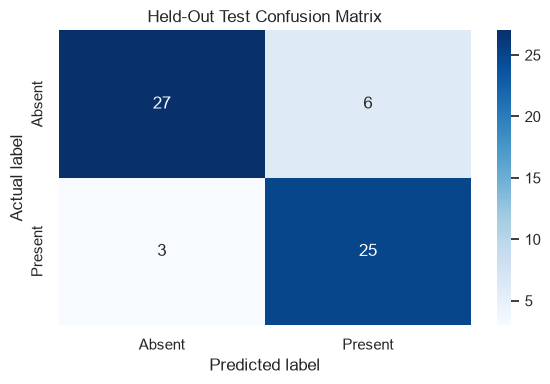

True negatives: 27
False positives: 6
False negatives: 3
True positives: 25


In [293]:
matrix = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))

sns.heatmap(
    matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Absent", "Present"],
    yticklabels=["Absent", "Present"]
)

plt.title("Held-Out Test Confusion Matrix")
plt.xlabel("Predicted label")
plt.ylabel("Actual label")

plt.tight_layout()
plt.show()

tn, fp, fn, tp = matrix.ravel()

print("True negatives:", tn)
print("False positives:", fp)
print("False negatives:", fn)
print("True positives:", tp)

### ROC Curve

The ROC curve displays the relationship between the true positive rate
and false positive rate as the decision threshold changes.

The dashed diagonal represents random ranking.

The curve uses SVC decision scores, not calibrated probabilities.

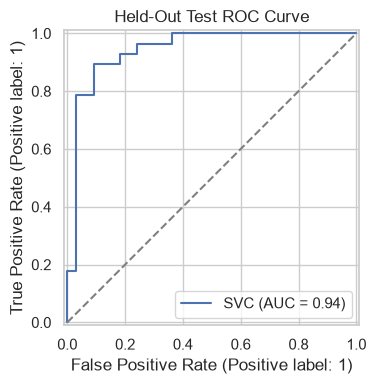

In [294]:
fig, ax = plt.subplots(figsize=(6, 4))

RocCurveDisplay.from_predictions(
    y_test,
    decision_scores,
    ax=ax,
    name="SVC"
)

ax.plot([0, 1], [0, 1], "--", color="gray")
ax.set_title("Held-Out Test ROC Curve")

plt.tight_layout()
plt.show()

## Step 8: Execute the Application Phase

An illustrative patient's attributes are entered using the original
UCI feature codes.

The saved pipeline handles preprocessing and returns a binary label.

This example is for demonstrating prediction only. It is not an
independent validation case or a medical diagnosis.

In [295]:
example_patient = pd.DataFrame([{
    "age": 63,
    "sex": 1,
    "cp": 1,
    "trestbps": 145,
    "chol": 233,
    "fbs": 1,
    "restecg": 2,
    "thalach": 150,
    "exang": 0,
    "oldpeak": 2.3,
    "slope": 3,
    "ca": 0,
    "thal": 6
}], columns=features)

prediction = int(loaded_model.predict(example_patient)[0])

print("Example input:")
print(example_patient.to_string(index=False))

print("\nPredicted label:",
      "Disease present (1)" if prediction == 1
      else "Disease absent (0)")

print("\nEducational model output; not a medical diagnosis.")

Example input:
 age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  ca  thal
  63    1   1       145   233    1        2      150      0      2.3      3   0     6

Predicted label: Disease absent (0)

Educational model output; not a medical diagnosis.


## Step 9: Execute the Feedback Phase

### Step 9.1: Collect Feedback

No real user or clinical feedback has been collected in this project.

A future review could record:
- Whether the input fields are understandable.
- Whether predictions agree with independently verified labels.
- Which cases produce false positives or false negatives.

### Step 9.2: Potential Improvements

- Compare one-hot encoding for categorical features.
- Compare SVC with other classifiers using training-only validation.
- Use a larger and more representative dataset.
- Evaluate performance on an independent external dataset.
- Examine performance across demographic subgroups.
- Assess calibration before displaying probability estimates.

### Step 9.3: Improve Based on Feedback

These improvements are proposals, not completed experiments.
Any revised model should be evaluated before replacing the saved model.

## Results Summary

The following cell summarizes the actual results produced by this
notebook. The reported test metrics apply only to the held-out subset
of the Cleveland dataset.

In [296]:
summary = pd.DataFrame({
    "Metric": [
        "Test accuracy",
        "Test precision",
        "Test recall",
        "Test F1",
        "Test ROC-AUC",
        "Mean training CV accuracy"
    ],
    "Value": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        cv_scores.mean()
    ]
})

print(summary.round(4).to_string(index=False))

print(
    f"\nThe model correctly classified {tn + tp} "
    f"of {len(y_test)} test observations."
)

print(
    f"It produced {fp} false positives "
    f"and {fn} false negatives."
)

                   Metric  Value
            Test accuracy 0.8525
           Test precision 0.8065
              Test recall 0.8929
                  Test F1 0.8475
             Test ROC-AUC 0.9437
Mean training CV accuracy 0.8223

The model correctly classified 52 of 61 test observations.
It produced 6 false positives and 3 false negatives.


## Conclusion and Limitations

This project demonstrates an end-to-end heart disease classification
workflow using the UCI processed Cleveland dataset and an SVC pipeline.

The pipeline handles missing inputs and feature scaling using only
training data. Evaluation includes training-only cross-validation and
held-out test metrics.

The reported performance does not establish clinical reliability.
The dataset is small and historical, and external validation has not
been performed.

The target represents recorded angiographic disease status.
It does not represent a prediction of future heart attacks.

## Step 10: Deployment Status

Cloud deployment is outside the current notebook-only stage.
The trained pipeline has been saved for use in a later deployment step.

## References

1. UCI Heart Disease dataset:
   https://archive.ics.uci.edu/dataset/45/heart+disease

2. Dataset DOI:
   https://doi.org/10.24432/C52P4X

3. Instructor's reference notebook:
   https://github.com/haqnawaz99/ml-teaching-notebooks

4. scikit-learn preprocessing and data leakage:
   https://scikit-learn.org/stable/common_pitfalls.html

5. scikit-learn SVC:
   https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVC.html

6. scikit-learn cross-validation:
   https://scikit-learn.org/stable/modules/cross_validation.html

7. scikit-learn evaluation metrics:
   https://scikit-learn.org/stable/modules/model_evaluation.html

8. scikit-learn model persistence:
   https://scikit-learn.org/stable/model_persistence.html

In [297]:
import pickle

with open("heart_disease_model.pkl", "rb") as file:
    saved_model = pickle.load(file)

print("Model loaded successfully!")

Model loaded successfully!


In [298]:
import sys
print(sys.executable)

c:\Users\User\AppData\Local\Programs\Python\Python313\python.exe


In [299]:
%pip install pandas streamlit scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [300]:
from importlib.metadata import version
from pathlib import Path

packages = ["streamlit", "pandas", "numpy", "scipy", "scikit-learn"]

requirements = "\n".join(
    f"{package}=={version(package)}"
    for package in packages
)

file_path = Path("requirements.txt")
file_path.write_text(requirements + "\n", encoding="utf-8")

print(requirements)
print("\nSaved at:", file_path.resolve())

streamlit==1.60.0
pandas==3.0.5
numpy==2.5.1
scipy==1.18.1
scikit-learn==1.9.1

Saved at: C:\Users\User\Desktop\Heart_Disease_Prediction\requirements.txt
